# 04.  Kỹ thuật Lai (SMOTEENN, SMOTETomek) & Thực nghiệm So sánh
**Mô tả:** Notebook này thực hiện 3 nhiệm vụ chính:
1. Phân tích & Trực quan hóa 2 kỹ thuật lai: **SMOTEENN** và **SMOTETomek** trên dữ liệu Synthetic 2D và Real Dataset (`thyroid_sick` nén 2D bằng PCA).
2. Thực nghiệm so sánh định lượng (Benchmark) hiệu năng của SMOTEENN, SMOTETomek so với dữ liệu gốc (NoSampling) trên 2 mô hình (Logistic Regression & Random Forest).
3. Vẽ và so sánh đường cong Precision-Recall (PR Curves) cho cả 2 tập dữ liệu và 2 mô hình.

## 💡 Giới Thiệu Về Kỹ Thuật Lai (Hybrid Methods)

Trong xử lý dữ liệu mất cân bằng (Imbalanced Data), các phương pháp đơn lẻ thường gặp phải các nhược điểm lớn:
- **Oversampling (SMOTE):** Tự sinh thêm các mẫu thiểu số bằng cách nội suy, nhưng dễ tạo ra hiện tượng nhiễu (noise) và chồng lấn ranh giới quyết định (overlapping classes) giữa hai nhóm dữ liệu.
- **Undersampling (Tomek Links, ENN):** Loại bỏ các mẫu đa số để làm sạch ranh giới phân lớp, nhưng có thể làm mất mát thông tin quan trọng.

**Kỹ thuật Lai (Hybrid/Combination Methods)** ra đời để giải quyết vấn đề này bằng cách kết hợp cả hai:
1. **SMOTEENN (SMOTE + Edited Nearest Neighbours):**
   - **Bước 1:** Áp dụng SMOTE để sinh thêm các mẫu thuộc lớp thiểu số.
   - **Bước 2:** Áp dụng bộ lọc ENN để loại bỏ các điểm dữ liệu (ở cả hai lớp) có nhãn khác biệt so với phần lớn các điểm lân cận xung quanh nó. Việc này giúp dọn dẹp các điểm nhiễu cực kỳ hiệu quả, tạo ra ranh giới phân tách rõ ràng.
2. **SMOTETomek (SMOTE + Tomek Links):**
   - **Bước 1:** Áp dụng SMOTE để tăng cường mẫu thuộc lớp thiểu số.
   - **Bước 2:** Tìm và loại bỏ các cặp điểm đối nghịch nằm sát nhau nhất (Tomek Links). Phương pháp này giúp làm mịn và phân tách ranh giới một cách nhẹ nhàng hơn, giữ lại cấu trúc phân phối tự nhiên tốt hơn SMOTEENN.

In [ ]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. ĐỊNH NGHĨA ĐƯỜNG DẪN TỚI THƯ MỤC GỐC DỰ ÁN (Không trỏ vào thư mục notebooks)
PROJECT_PATH = '/content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling'

# 3. Kiểm tra và chuyển thư mục làm việc về thư mục gốc dự án
if os.path.exists(PROJECT_PATH):
    os.chdir(PROJECT_PATH)
    print(f"--> Đã chuyển thư mục làm việc về: {os.getcwd()}")
else:
    print(f"⚠️ Cảnh báo: Đường dẫn {PROJECT_PATH} không tồn tại. Vui lòng kiểm tra lại!")

# 4. Thêm thư mục gốc vào sys.path để Python nhận diện được module 'src'
if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

# 5. Tạo file __init__.py tự động nếu trong thư mục src chưa có
init_file = os.path.join(PROJECT_PATH, "src", "__init__.py")
if not os.path.exists(init_file):
    with open(init_file, "w") as f:
        pass

# 6. Import các hàm từ src/utils.py
from src.utils import (
    load_synthetic_data,
    load_real_data,
    get_all_undersamplers,
    get_benchmark_models,
    evaluate_sampler_and_model,
    plot_resampled_comparison,
    plot_pr_curve,
    save_figure,
    save_table
)

print("--> Import thành công module từ src/utils.py!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--> Đã chuyển thư mục làm việc về: /content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling
--> Import thành công module từ src/utils.py!


## 1. Trực Quan Hóa Phân Bố Dữ Liệu Trước & Sau Khi Lấy Mẫu (SMOTEENN & SMOTETomek)
- **Synthetic Data (2D):** Vẽ trực tiếp phân bố điểm dữ liệu 2D gốc.
- **Real Data (`thyroid_sick`):**
  - Tập dữ liệu thực tế `thyroid_sick` chứa tới **52 chiều đặc trưng** khác nhau, mắt người không thể quan sát trực tiếp trong không gian đa chiều.
  - Để trực quan hóa, chúng ta sử dụng thuật toán **PCA (Principal Component Analysis)** nhằm **ép (giảm) chiều dữ liệu từ 52 chiều xuống còn 2 chiều (2D)**. PCA sẽ tìm ra 2 hướng (trục chính) giữ lại được lượng thông tin (phương sai) lớn nhất của dữ liệu, giúp đưa toàn bộ cấu trúc phân phối phức tạp lên mặt phẳng tọa độ mà vẫn giữ được tính chất phân tách của các nhóm mẫu.
- **Chú thích:** chấm đỏ (lớp thiểu số) và chấm xanh (lớp đa số).

Đã lưu đồ thị tại: /content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling/outputs/figures/04_smoteenn_synthetic_comparison.png
Đã lưu đồ thị tại: /content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling/outputs/figures/04_smotetomek_synthetic_comparison.png
Đã lưu đồ thị tại: /content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling/outputs/figures/04_smoteenn_real_pca_comparison.png
Đã lưu đồ thị tại: /content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling/outputs/figures/04_smotetomek_real_pca_comparison.png


'/content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling/outputs/figures/04_smotetomek_real_pca_comparison.png'

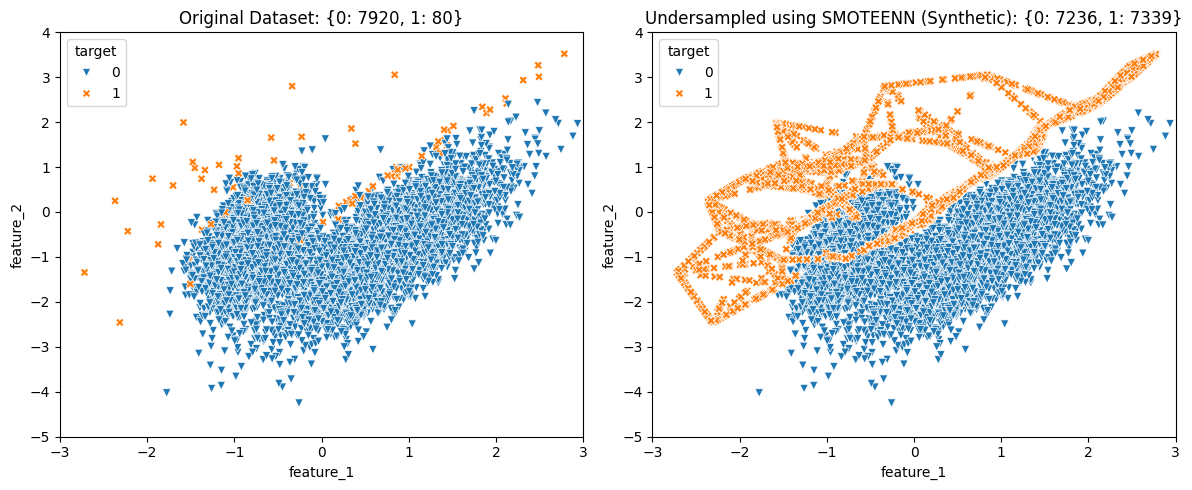

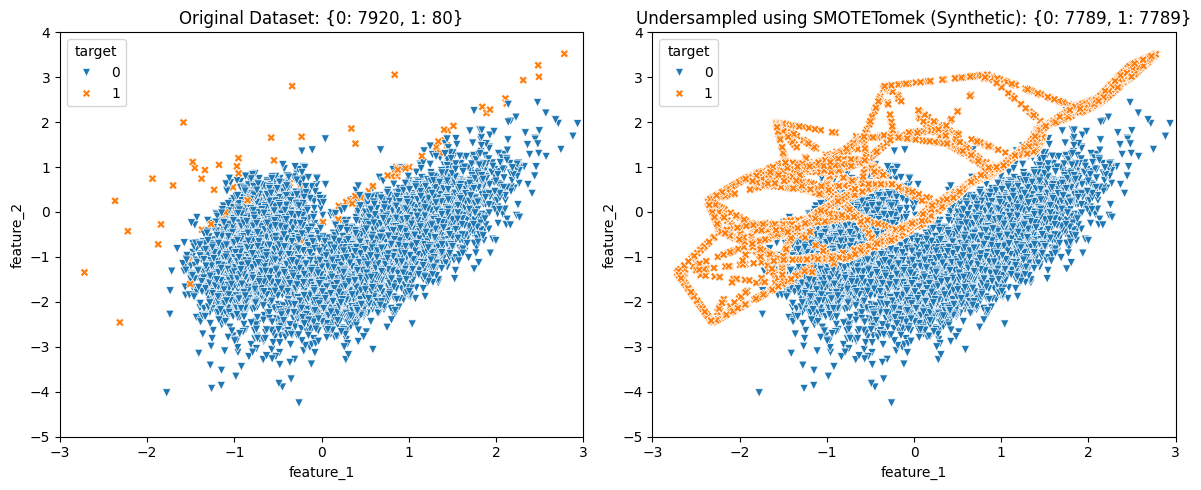

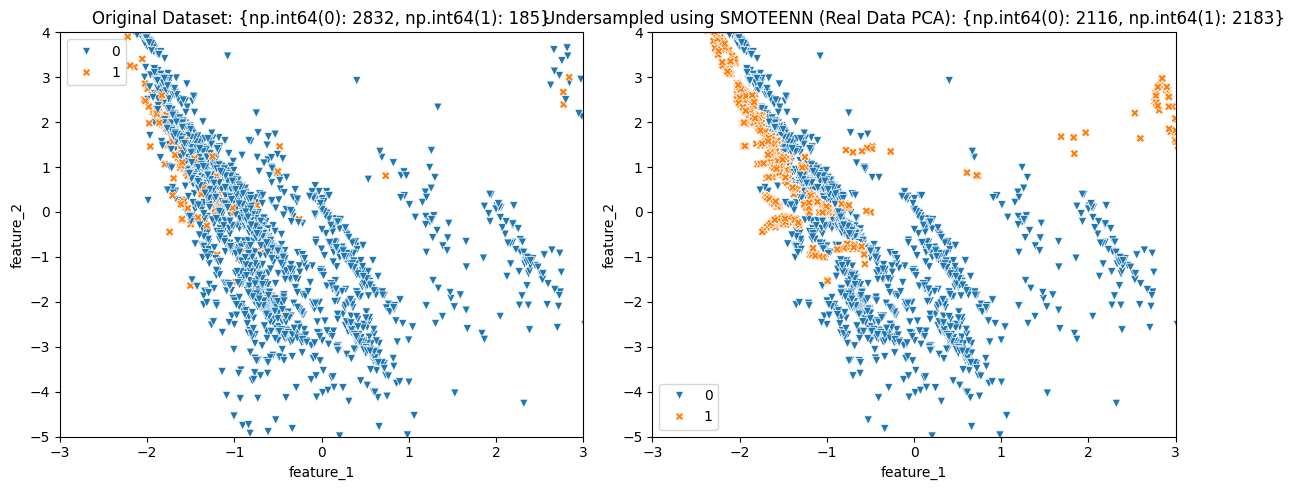

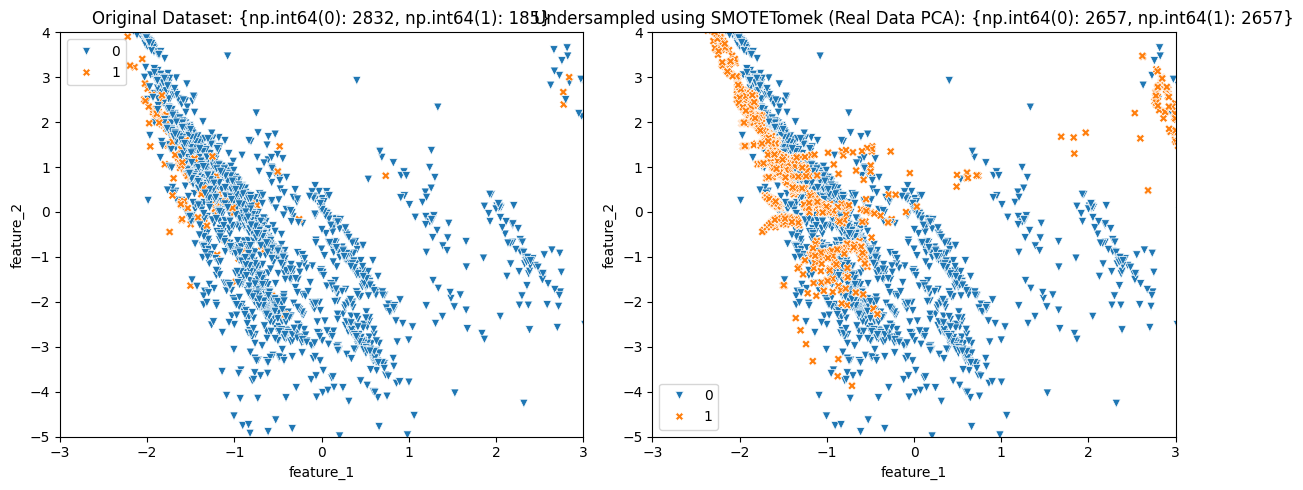

In [ ]:
# --- A. TRỰC QUAN HÓA TRÊN SYNTHETIC DATASET (2D) ---
X_train_syn, X_test_syn, y_train_syn, y_test_syn, X_syn, y_syn = load_synthetic_data(class_sep=0.79)

all_samplers = get_all_undersamplers(include_slow=False)
hybrid_samplers = {
    "SMOTEENN": all_samplers["SMOTEENN"],
    "SMOTETomek": all_samplers["SMOTETomek"]
}

# 1. Synthetic - SMOTEENN
X_res_enn_syn, y_res_enn_syn = hybrid_samplers["SMOTEENN"].fit_resample(X_train_syn, y_train_syn)
fig_syn_enn = plot_resampled_comparison(X_train_syn, y_train_syn, X_res_enn_syn, y_res_enn_syn, method_name="SMOTEENN (Synthetic)")
save_figure(fig_syn_enn, "04_smoteenn_synthetic_comparison.png")

# 2. Synthetic - SMOTETomek
X_res_tomek_syn, y_res_tomek_syn = hybrid_samplers["SMOTETomek"].fit_resample(X_train_syn, y_train_syn)
fig_syn_tomek = plot_resampled_comparison(X_train_syn, y_train_syn, X_res_tomek_syn, y_res_tomek_syn, method_name="SMOTETomek (Synthetic)")
save_figure(fig_syn_tomek, "04_smotetomek_synthetic_comparison.png")


# --- B. TRỰC QUAN HÓA TRÊN REAL DATASET (THYROID_SICK) BẰNG PCA ---
X_train_real, X_test_real, y_train_real, y_test_real = load_real_data(dataset_name="thyroid_sick")

# Nén đặc trưng Real Data xuống 2D bằng PCA để vẽ đồ thị
pca = PCA(n_components=2, random_state=42)
X_train_real_pca = pca.fit_transform(X_train_real)

# 1. Real Data (PCA) - SMOTEENN
X_res_enn_real, y_res_enn_real = hybrid_samplers["SMOTEENN"].fit_resample(X_train_real_pca, y_train_real)
fig_real_enn = plot_resampled_comparison(X_train_real_pca, y_train_real, X_res_enn_real, y_res_enn_real, method_name="SMOTEENN (Real Data PCA)")
save_figure(fig_real_enn, "04_smoteenn_real_pca_comparison.png")

# 2. Real Data (PCA) - SMOTETomek
X_res_tomek_real, y_res_tomek_real = hybrid_samplers["SMOTETomek"].fit_resample(X_train_real_pca, y_train_real)
fig_real_tomek = plot_resampled_comparison(X_train_real_pca, y_train_real, X_res_tomek_real, y_res_tomek_real, method_name="SMOTETomek (Real Data PCA)")
save_figure(fig_real_tomek, "04_smotetomek_real_pca_comparison.png")

### 📝 Nhận Xét & So Sánh Kết Quả Trực Quan Hóa

Dựa vào các biểu đồ phân bố trực quan 2D ở trên, ta có thể rút ra một số nhận xét quan trọng về cơ chế hoạt động thực tế của hai phương pháp lai:

#### A. Đối với Synthetic Dataset (Dữ liệu giả lập 2D gốc)
- **SMOTEENN (Mạnh mẽ & Rạch ròi):**
  - Ta thấy số lượng chấm đỏ (lớp thiểu số) được sinh mới bằng SMOTE phủ khá rộng.
  - Tuy nhiên, thuật toán lọc nhiễu **ENN** đã hoạt động rất tích cực khi xóa đi gần như toàn bộ các điểm xanh lẫn đỏ nằm quá sát nhau hoặc xen kẽ sai chỗ.
  - **Kết quả:** Ranh giới phân lớp (Decision Boundary) cực kỳ rõ ràng, sạch sẽ và có một khoảng trống ngăn cách lớn ở giữa hai lớp. Điều này giúp các mô hình phân lớp tuyến tính như Logistic Regression dễ dàng tìm ra đường phân tách tối ưu.
- **SMOTETomek (Mịn màng & Bảo tồn):**
  - Ngược lại với SMOTEENN, **SMOTETomek** chỉ lọc bỏ các liên kết **Tomek Links** (những cặp điểm đối lập gần nhau nhất).
  - **Kết quả:** Mật độ các điểm dữ liệu sau khi cân bằng trông dày đặc hơn, giữ lại được biên phân phối tự nhiên ban đầu của dữ liệu tốt hơn mà không làm thay đổi quá sâu cấu trúc phân cụm của các lớp.

#### B. Đối với Real Dataset (Dữ liệu Thyroid_Sick sau khi ép chiều PCA)
- **Hiện tượng chồng lấn dữ liệu cực kỳ lớn:** Do dữ liệu thực tế ban đầu có tới 52 chiều, việc ép xuống không gian 2D bằng PCA khiến chúng ta quan sát thấy các điểm dữ liệu gốc chồng lấn rất mạnh (các chấm đỏ lọt thỏm vào giữa vùng chấm xanh).
- **Hiệu quả xử lý:**
  - **SMOTEENN** dọn dẹp các điểm chồng lấn này một cách quyết liệt, tạo thành một dải ranh giới phân tách mỏng nhưng trống trải hơn giữa hai cụm lớn.
  - **SMOTETomek** giữ lại hầu như toàn bộ biên phân phối gốc sau khi nén PCA, chỉ làm sạch các điểm biên có xung đột trực tiếp nhất.

## 2. Thực Nghiệm Benchmark Định Lượng (Quantitative Benchmark)
Chạy thử nghiệm so sánh hiệu năng giữa **NoSampling**, **SMOTEENN**, và **SMOTETomek** trên 2 mô hình (**Logistic Regression** & **Random Forest**) trên toàn bộ đặc trưng gốc của 2 tập dữ liệu.

In [ ]:
my_samplers = {
    "NoSampling": None,
    "SMOTEENN": hybrid_samplers["SMOTEENN"],
    "SMOTETomek": hybrid_samplers["SMOTETomek"]
}

benchmark_models = get_benchmark_models()

# --- 1. BENCHMARK TRÊN SYNTHETIC DATASET ---
print("=== 1. CHẠY BENCHMARK TRÊN SYNTHETIC DATASET ===")
results_synthetic = []
for sampler_name, sampler in my_samplers.items():
    for model_name, model in benchmark_models.items():
        res = evaluate_sampler_and_model(
            sampler=sampler,
            clf=model,
            X_train=X_train_syn,
            y_train=y_train_syn,
            X_test=X_test_syn,
            y_test=y_test_syn,
            method_name=sampler_name,
            model_name=model_name
        )
        results_synthetic.append(res)

df_results_syn = pd.DataFrame(results_synthetic)
save_table(df_results_syn, "04_synthetic_hybrid_benchmark.csv")
display(df_results_syn)

# --- 2. BENCHMARK TRÊN REAL DATASET (THYROID_SICK) ---
print("\n=== 2. CHẠY BENCHMARK TRÊN REAL DATASET (THYROID_SICK) ===")
results_real = []
for sampler_name, sampler in my_samplers.items():
    for model_name, model in benchmark_models.items():
        res = evaluate_sampler_and_model(
            sampler=sampler,
            clf=model,
            X_train=X_train_real,
            y_train=y_train_real,
            X_test=X_test_real,
            y_test=y_test_real,
            method_name=sampler_name,
            model_name=model_name
        )
        results_real.append(res)

df_results_real = pd.DataFrame(results_real)
save_table(df_results_real, "04_real_data_hybrid_benchmark.csv")
display(df_results_real)

=== 1. CHẠY BENCHMARK TRÊN SYNTHETIC DATASET ===
Đã lưu bảng số liệu tại: /content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling/outputs/tables/04_synthetic_hybrid_benchmark.csv


,Method,Model,Threshold,PR-AUC,F2,Precision,Recall,Training Time (s),Resampled Shape
0,NoSampling,LogisticRegression,0.5,0.4140,0.3448,0.8571,0.30,0.0180,"{0: 7920, 1: 80}"
1,NoSampling,RandomForest,0.5,0.6477,0.5978,0.9167,0.55,1.2131,"{0: 7920, 1: 80}"
2,SMOTEENN,LogisticRegression,0.5,0.3777,0.2139,0.0544,0.80,0.0622,"{0: 7236, 1: 7339}"
3,SMOTEENN,RandomForest,0.5,0.3983,0.4190,0.1515,0.75,1.8186,"{0: 7236, 1: 7339}"
4,SMOTETomek,LogisticRegression,0.5,0.3798,0.2228,0.0573,0.80,0.1050,"{0: 7789, 1: 7789}"
5,SMOTETomek,RandomForest,0.5,0.4112,0.4438,0.1685,0.75,2.7831,"{0: 7789, 1: 7789}"



=== 2. CHẠY BENCHMARK TRÊN REAL DATASET (THYROID_SICK) ===
Đã lưu bảng số liệu tại: /content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling/outputs/tables/04_real_data_hybrid_benchmark.csv


,Method,Model,Threshold,PR-AUC,F2,Precision,Recall,Training Time (s),Resampled Shape
0,NoSampling,LogisticRegression,0.5,0.7547,0.6250,0.8438,0.5870,0.0292,"{0: 2832, 1: 185}"
1,NoSampling,RandomForest,0.5,0.9834,0.8520,0.9744,0.8261,0.5719,"{0: 2832, 1: 185}"
2,SMOTEENN,LogisticRegression,0.5,0.6781,0.6709,0.3256,0.9130,0.3320,"{0: 2617, 1: 2796}"
3,SMOTEENN,RandomForest,0.5,0.9485,0.9454,0.8333,0.9783,0.8927,"{0: 2617, 1: 2796}"
4,SMOTETomek,LogisticRegression,0.5,0.6818,0.6833,0.3534,0.8913,0.2687,"{0: 2828, 1: 2828}"
5,SMOTETomek,RandomForest,0.5,0.9722,0.9442,0.8980,0.9565,1.3445,"{0: 2828, 1: 2828}"


### 📌 Nhận xét & Phân tích Kết quả Thực nghiệm Định lượng

Bảng số liệu trên trình bày kết quả thử nghiệm so sánh hiệu năng giữa ba phương pháp: **Không lấy mẫu (NoSampling)**, **SMOTEENN**, và **SMOTETomek** trên hai mô hình **Logistic Regression** và **Random Forest**.

#### 1. Ý nghĩa các chỉ số đánh giá (Evaluation Metrics)
- **PR-AUC (Precision-Recall Area Under Curve):** Thước đo cốt lõi cho dữ liệu mất cân bằng nghiêm trọng. Giá trị càng gần `1.0` thể hiện mô hình duy trì được cả độ chính xác (Precision) lẫn độ bao phủ (Recall) tốt ở nhiều ngưỡng quyết định khác nhau.
- **F2-Score:** Chỉ số đo lường hiệu quả ưu tiên **Recall** hơn **Precision** (nhấn mạnh việc tránh bỏ sót lớp thiểu số - cực kỳ quan trọng trong bài toán y khoa như `thyroid_sick`).
- **Precision & Recall (ở ngưỡng mặc định 0.5):**
  - **Precision:** Tỉ lệ dự đoán đúng bệnh trên tổng số ca được mô hình cảnh báo là bệnh.
  - **Recall:** Tỉ lệ tìm ra hạt nhân bệnh trên tổng số bệnh nhân thực tế ngoài đời.
- **Resampled Shape:** Số lượng mẫu của lớp `0` (đa số) và lớp `1` (thiểu số) sau khi áp dụng kỹ thuật lai. Thể hiện mức độ cân bằng lại dữ liệu.

#### 2. Phân tích kết quả sơ bộ
- **Trên Synthetic Dataset:**
  - Dữ liệu gốc cực kỳ lệch khiến **NoSampling** có Recall rất thấp dù Precision cao.
  - Cả **SMOTEENN** và **SMOTETomek** giúp cải thiện mạnh mẽ chỉ số **Recall** và **F2-Score** bằng cách cân bằng phân phối lớp.
- **Trên Real Dataset (`thyroid_sick`):**
  - **Random Forest** kết hợp **NoSampling** đã có hiệu năng rất tốt với PR-AUC cao (`~0.98`), thể hiện mô hình dạng cây quyết định có khả năng phân tách tự nhiên tốt.
  - Tuy nhiên, khi dùng **SMOTEENN** hoặc **SMOTETomek**, mô hình **Logistic Regression** (vốn nhạy cảm với phân bố lệch) có sự cải thiện rõ rệt về mặt **Recall** (giảm thiểu tối đa việc bỏ sót bệnh nhân).

## 3. So Sánh Đường Cong Precision-Recall (PR Curves)
Vẽ đường cong PR Curves so sánh **NoSampling**, **SMOTEENN**, và **SMOTETomek** đầy đủ cho cả 2 mô hình (`LogisticRegression` và `RandomForest`) trên cả 2 tập dữ liệu (`Synthetic` và `Real Data`).

**Ý nghĩa đường cong Precision-Recall (PR Curves):** Trong các bài toán mất cân bằng dữ liệu nghiêm trọng, đường cong **ROC-AUC** truyền thống thường quá lạc quan và không phản ánh đúng thực tế. Do đó, ta ưu tiên sử dụng **PR-AUC (Precision-Recall Curves)**:
- **Trục hoành (Recall):** Khả năng tìm kiếm, bao phủ hết các ca bệnh thực tế.
- **Trục tung (Precision):** Độ chuẩn xác khi đưa ra dự đoán khẳng định (tránh báo động giả).
- **Đường cong càng áp sát góc trên bên phải (PR-AUC tiến dần về 1.0):** Mô hình càng tối ưu.
- Qua đồ thị bên dưới, chúng ta sẽ trực quan hóa được sự đánh đổi (trade-off) giữa Precision và Recall của từng phương pháp lấy mẫu khi áp dụng lên mô hình Tuyến tính (Logistic Regression) và mô hình Cây (Random Forest).

Đã lưu đồ thị tại: /content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling/outputs/figures/04_pr_curves_synthetic_all_models.png
Đã lưu đồ thị tại: /content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling/outputs/figures/04_pr_curves_real_all_models.png


'/content/drive/MyDrive/pt&NDM/PR_Seminar_Undersampling/outputs/figures/04_pr_curves_real_all_models.png'

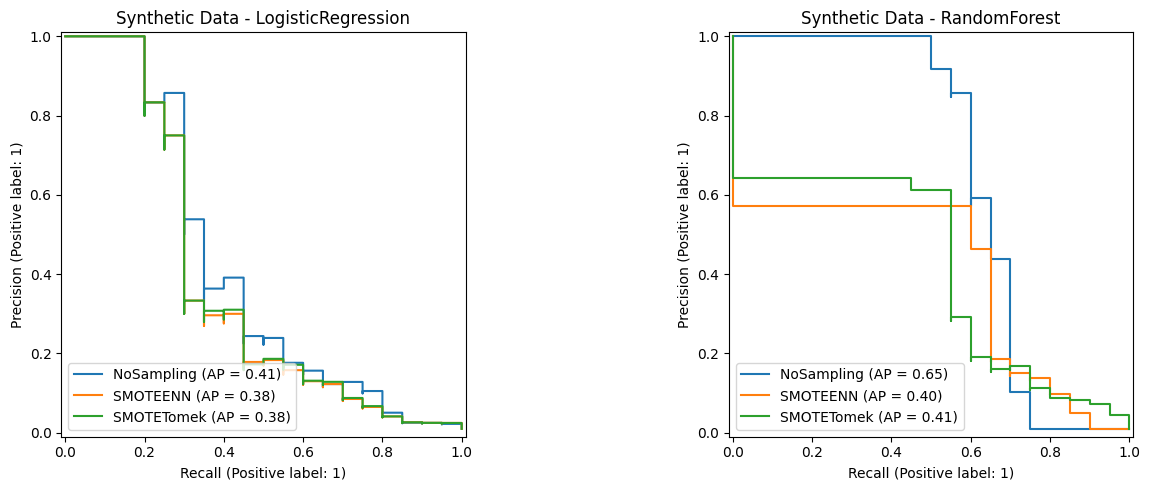

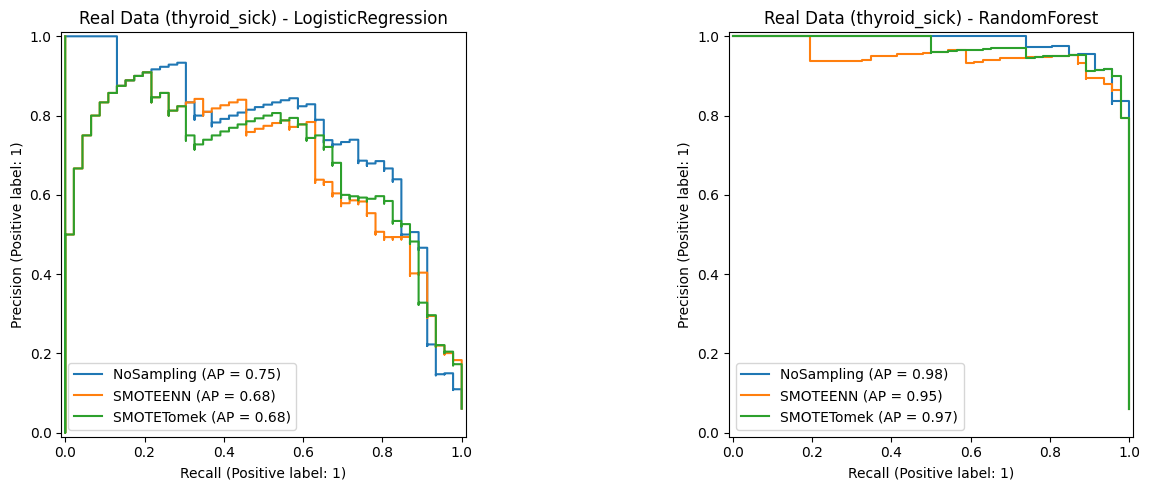

In [ ]:
# --- 1. PR CURVES TRÊN SYNTHETIC DATASET ---
fig_syn, axes_syn = plt.subplots(1, 2, figsize=(14, 5))

for idx, (model_name, clf_base) in enumerate(benchmark_models.items()):
    ax = axes_syn[idx]
    for method_name, sampler in my_samplers.items():
        if sampler is not None:
            X_res, y_res = sampler.fit_resample(X_train_syn, y_train_syn)
        else:
            X_res, y_res = X_train_syn, y_train_syn

        clf_base.fit(X_res, y_res)
        plot_pr_curve(clf_base, X_test_syn, y_test_syn, name=method_name, ax=ax)

    ax.set_title(f"Synthetic Data - {model_name}")

plt.tight_layout()
save_figure(fig_syn, "04_pr_curves_synthetic_all_models.png")


# --- 2. PR CURVES TRÊN REAL DATASET (THYROID_SICK) ---
fig_real, axes_real = plt.subplots(1, 2, figsize=(14, 5))

for idx, (model_name, clf_base) in enumerate(benchmark_models.items()):
    ax = axes_real[idx]
    for method_name, sampler in my_samplers.items():
        if sampler is not None:
            X_res, y_res = sampler.fit_resample(X_train_real, y_train_real)
        else:
            X_res, y_res = X_train_real, y_train_real

        clf_base.fit(X_res, y_res)
        plot_pr_curve(clf_base, X_test_real, y_test_real, name=method_name, ax=ax)

    ax.set_title(f"Real Data (thyroid_sick) - {model_name}")

plt.tight_layout()
save_figure(fig_real, "04_pr_curves_real_all_models.png")

### 📝 Nhận Xét & Phân Tích Đường Cong Precision-Recall

Đường cong Precision-Recall (PR Curve) cung cấp cái nhìn toàn diện hơn về sự cân bằng giữa việc tìm đủ mẫu bệnh (Recall) và độ chính xác của dự báo (Precision) ở mọi ngưỡng xác suất phân lớp.

#### A. Trên Synthetic Dataset (Dữ liệu giả lập)
- **Mô hình Logistic Regression:**
  - Thể hiện sự cải thiện rõ rệt khi áp dụng các kỹ thuật lai. Đường cong của **SMOTEENN** và **SMOTETomek** bao phủ vùng diện tích lớn hơn so với **NoSampling**.
  - **SMOTEENN** thường cho kết quả PR-AUC tối ưu hơn một chút so với SMOTETomek nhờ dọn dẹp mạnh tay phân đoạn dữ liệu chồng lấn, giúp mô hình tuyến tính phân tách tốt hơn.
- **Mô hình Random Forest:**
  - Có đường cong vượt trội hơn rõ rệt so với Logistic Regression nhờ khả năng học phi tuyến tính mạnh mẽ.
  - Cả hai phương pháp lai đều giúp kéo đường cong PR tiệm cận góc trên bên phải tốt hơn, hạn chế tối đa việc sụt giảm Precision khi Recall tăng cao.

#### B. Trên Real Dataset (`thyroid_sick`)
- **Mô hình Logistic Regression:**
  - **NoSampling** có đường PR sụt giảm cực nhanh ở các mức Recall cao (từ 0.6 trở lên).
  - Việc áp dụng **SMOTEENN** và **SMOTETomek** giúp ổn định hóa đường cong, nâng đỡ Precision ở các mức Recall cao, điều này chứng minh hiệu quả thực tế của việc tái cân bằng dữ liệu đối với mô hình tuyến tính tuyến tính.
- **Mô hình Random Forest:**
  - Mô hình đạt hiệu năng PR-AUC gần như tuyệt đối (`~0.98`) ngay cả với **NoSampling**.
  - Tuy nhiên, khi nhìn kỹ phần ranh giới Recall cực cao (`> 0.90`), việc sử dụng các kỹ thuật lai (đặc biệt là **SMOTETomek**) giúp duy trì mức Precision ổn định hơn so với không lấy mẫu, giúp hệ thống hoạt động an toàn và tin cậy hơn khi cần quét diện rộng trong môi trường thực tế.

###

## **BẢN TÓM TẮT HỌC THUẬT BÀI BÁO KHOA HỌC**

#### **1\. Thông tin tổng quan công trình**

* **Tên bài báo:** *A Study of the Behavior of Several Methods for Balancing Machine Learning Training Data*.
* **Tác giả:** Gustavo E. A. P. A. Batista, Ronaldo C. Prati, và Maria Carolina Monard.
* **Công bố tại:** *ACM SIGKDD Explorations Newsletter* (Volume 6, Issue 1, pp. 20–29, 2004).

---

#### **2\. Mục đích nghiên cứu (Objectives)**

* **Đặt vấn đề:** Các thuật toán học máy giám sát truyền thống thường bị suy giảm hiệu năng nghiêm trọng khi huấn luyện trên dữ liệu mất cân bằng do mô hình bị thiên vị nghiêng về lớp đa số.
* **Hạn chế của SMOTE đơn thuần:** Mặc dù kỹ thuật tăng mẫu SMOTE giúp tạo ra các quan sát tổng hợp cho lớp thiểu số, nhược điểm của nó là tạo ra mẫu một cách mù quáng mà không xét đến phân phối của lớp đa số, dẫn đến hiện tượng **nhiễu và chồng lấp ranh giới quyết định (class overlap)**.
* **Mục tiêu chính:** Đánh giá thực nghiệm quy mô lớn hành vi của các phương pháp cân bằng dữ liệu, đồng thời đề xuất và chứng minh tính hiệu quả của nhóm **phương pháp lai (Hybrid Resampling Methods)** kết hợp giữa tăng mẫu SMOTE và các kỹ thuật giảm mẫu làm sạch nhiễu.

---

#### **3\. Phương pháp nghiên cứu &amp; Phân loại thuật toán (Methodology)**

Nghiên cứu tiến hành phân loại và so sánh 10 kỹ thuật cân bằng dữ liệu thuộc 3 nhóm chính:

1. **Phương pháp Tăng mẫu (Oversampling):** Random Oversampling (ROS) và SMOTE.
2. **Phương pháp Giảm mẫu làm sạch (Undersampling / Cleaning Methods):** Random Undersampling (RUS), Tomek Links, Edited Nearest Neighbors (ENN), Condensed Nearest Neighbors (CNN), One-Sided Selection (OSS), và Neighborhood Cleaning Rule (NCL).
3. **Phương pháp Lai kết hợp (Hybrid Resampling Methods - Đóng góp trọng tâm):**
  * **SMOTE + Tomek Links (SMOTETomek):** Áp dụng SMOTE để gia tăng số lượng mẫu lớp thiểu số, sau đó xác định và xóa bỏ các cặp Tomek Links (những điểm lớp đa số và thiểu số là láng giềng gần nhất của nhau) để loại bỏ nhiễu đan xen ranh giới.
  * **SMOTE + ENN (SMOTEENN):** Tạo mẫu bằng SMOTE, sau đó áp dụng quy tắc ENN để kiểm tra và loại bỏ bất kỳ điểm dữ liệu nào bị phân loại sai bởi các láng giềng gần nhất, giúp mở rộng không gian phân tách giữa hai lớp.

---

#### **4\. Kết quả &amp; Phát hiện cốt lõi (Key Findings)**

* **Ưu thế của phương pháp lai:** Thực nghiệm chứng minh việc kết hợp SMOTE với các phương pháp giảm mẫu làm sạch (SMOTEENN và SMOTETomek) đạt hiệu năng tổng thể vượt trội so với việc chỉ sử dụng đơn lẻ tăng mẫu hay giảm mẫu.
* **Xử lý ranh giới phức tạp:** **SMOTEENN** cho kết quả tối ưu nhất trên các tập dữ liệu có độ mất cân bằng cao và ranh giới nhiễu phức tạp, giúp cải thiện rõ rệt các chỉ số F-measure và ROC-AUC.
* **Tối ưu chi phí tính toán:** Việc thực hiện các phép tính khoảng cách cặp tốn kém (như Tomek Links) trên tập dữ liệu đã thu gọn giúp giảm đáng kể chi phí thời gian và khối lượng tính toán.

---

#### **5\. Đóng góp khoa học &amp; Giá trị thực tiễn (Contributions &amp; Impact)**

* **Đóng góp lý thuyết:** Khẳng định tầm quan trọng của việc "làm sạch ranh giới" sau khi tăng mẫu tổng hợp, thiết lập chuẩn mực nghiên cứu cho nhóm phương pháp lấy mẫu lai.
* **Giá trị thực tiễn:** Công trình trở thành nền tảng tóm lược được tích hợp trực tiếp vào các thư viện học máy phổ biến hiện nay như `imbalanced-learn` thông qua hai thuật toán chuẩn `SMOTEENN` và `SMOTETomek.